# [Lab Session 2](otsu.ipynb)

In [7]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 2.1.]()** Implement Otsu thresholding as a re-usable function:

In [8]:
def otsu_thresholding(imgf):
    img8 = (imgf * 255).round().astype(np.uint8)
    otsu = []
    for T in range (0,255):
        class1 = img8[img8<T]
        class2 = img8[img8>=T]
        if len(class1) == 0 or len(class2) == 0:
            otsu.append (np.inf)
        else:
            otsu.append (len(class1)*np.var(class1) + len(class2)*np.var(class2))
    T = np.argmin (otsu)
    seg = img8 >= T 
    return seg

**[Task 2.2.]()** Implement a re-usable function to compute the Dice coefficient:

In [9]:
def compute_dice(bin1, bin2):
    assert bin1.dtype == bool
    assert bin2.dtype == bool
    
    dice = 2*(bin1*bin2).sum()/(bin1.sum()+bin2.sum())
    
    return dice

**[Task 2.3.]()** Test your implementations from above:

In [10]:
img2 = plt.imread('data/NIH3T3/im/dna-0.png')
gt = plt.imread ('data/NIH3T3/gt/0.png').astype(bool)
print(compute_dice(otsu_thresholding (img2), gt))

0.8943783223933183


The result should be the same as in your [otsu.ipynb](otsu.ipynb) notebook.

**[Task 2.4.]()** Perform batch processing:

In [11]:
dice = []
for i in [28, 29, 33, 44, 46, 49]:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread (f'data/NIH3T3/gt/{i}.png').astype(bool)
    otsu = otsu_thresholding (img2)
    diced = compute_dice (otsu, gt)
    dice.append(diced)
    print (i, diced)
print (np.mean(dice))


28 0.17079535733980608
29 0.15751715605909453
33 0.1641838844865765
44 0.22793496507769898
46 0.19254944714022604
49 0.1318754286881777
0.1741427064652633


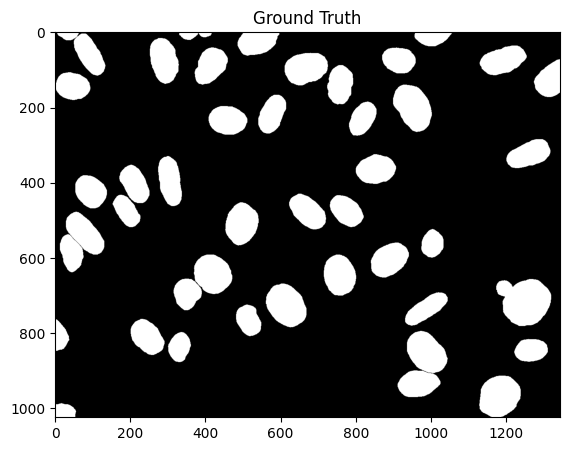

In [12]:
img = plt.imread('data/NIH3T3/im/dna-28.png')
gt = plt.imread('data/NIH3T3/gt/28.png').astype(bool)
seg = otsu_thresholding(img)

plt.figure(figsize=(10, 5))

plt.imshow(seg, cmap='gray')
plt.title('Otsu')

plt.imshow(gt, cmap='gray')
plt.title('Ground Truth')

plt.show()